In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import pytesseract
from IPython.display import display
from PIL import Image

from doc_verify.config import DATA_DIR
from doc_verify.tobacco import load_tobacco, to_200_dpi
from sad_syn.analysis import (
    ablate_leave_one_out,
    ablate_one_at_a_time,
    compare_candidates,
    compare_confidence,
    label_gap_tests,
    ocr_accuracy,
    strength_summary,
)
from sad_syn.degrade import degrade
from sad_syn.doc_types import DOC_TYPES, render_document, rule_test
from sad_syn.generate import (
    make_clean_offer,
    make_inconsistent_offer,
    make_letters,
    set_seed,
)
from sad_syn.ocr import check_ocr, page_confidences
from sad_syn.pipeline import DEGRADE_SEED, run_ocr, run_ocr_sampled, swapped_seeds
from sad_syn.render import render_offer, template_01

set_seed(42)

samples_dir = DATA_DIR / "samples"
samples_dir.mkdir(parents=True, exist_ok=True)

In [2]:
for doc_type in DOC_TYPES:
    print(doc_type, rule_test(doc_type, 1000))

offer_letter {'clean': 1000, 'altered_date': 1000, 'altered_amount': 1000, 'institution_mismatch': 1000, 'total_mismatch': 1000}


transcript {'clean': 1000, 'altered_date': 1000, 'altered_amount': 1000, 'institution_mismatch': 1000, 'total_mismatch': 1000}


bank_statement {'clean': 1000, 'altered_date': 1000, 'altered_amount': 1000, 'institution_mismatch': 1000, 'total_mismatch': 1000}


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/clean_letter.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/altered_amount_letter.png


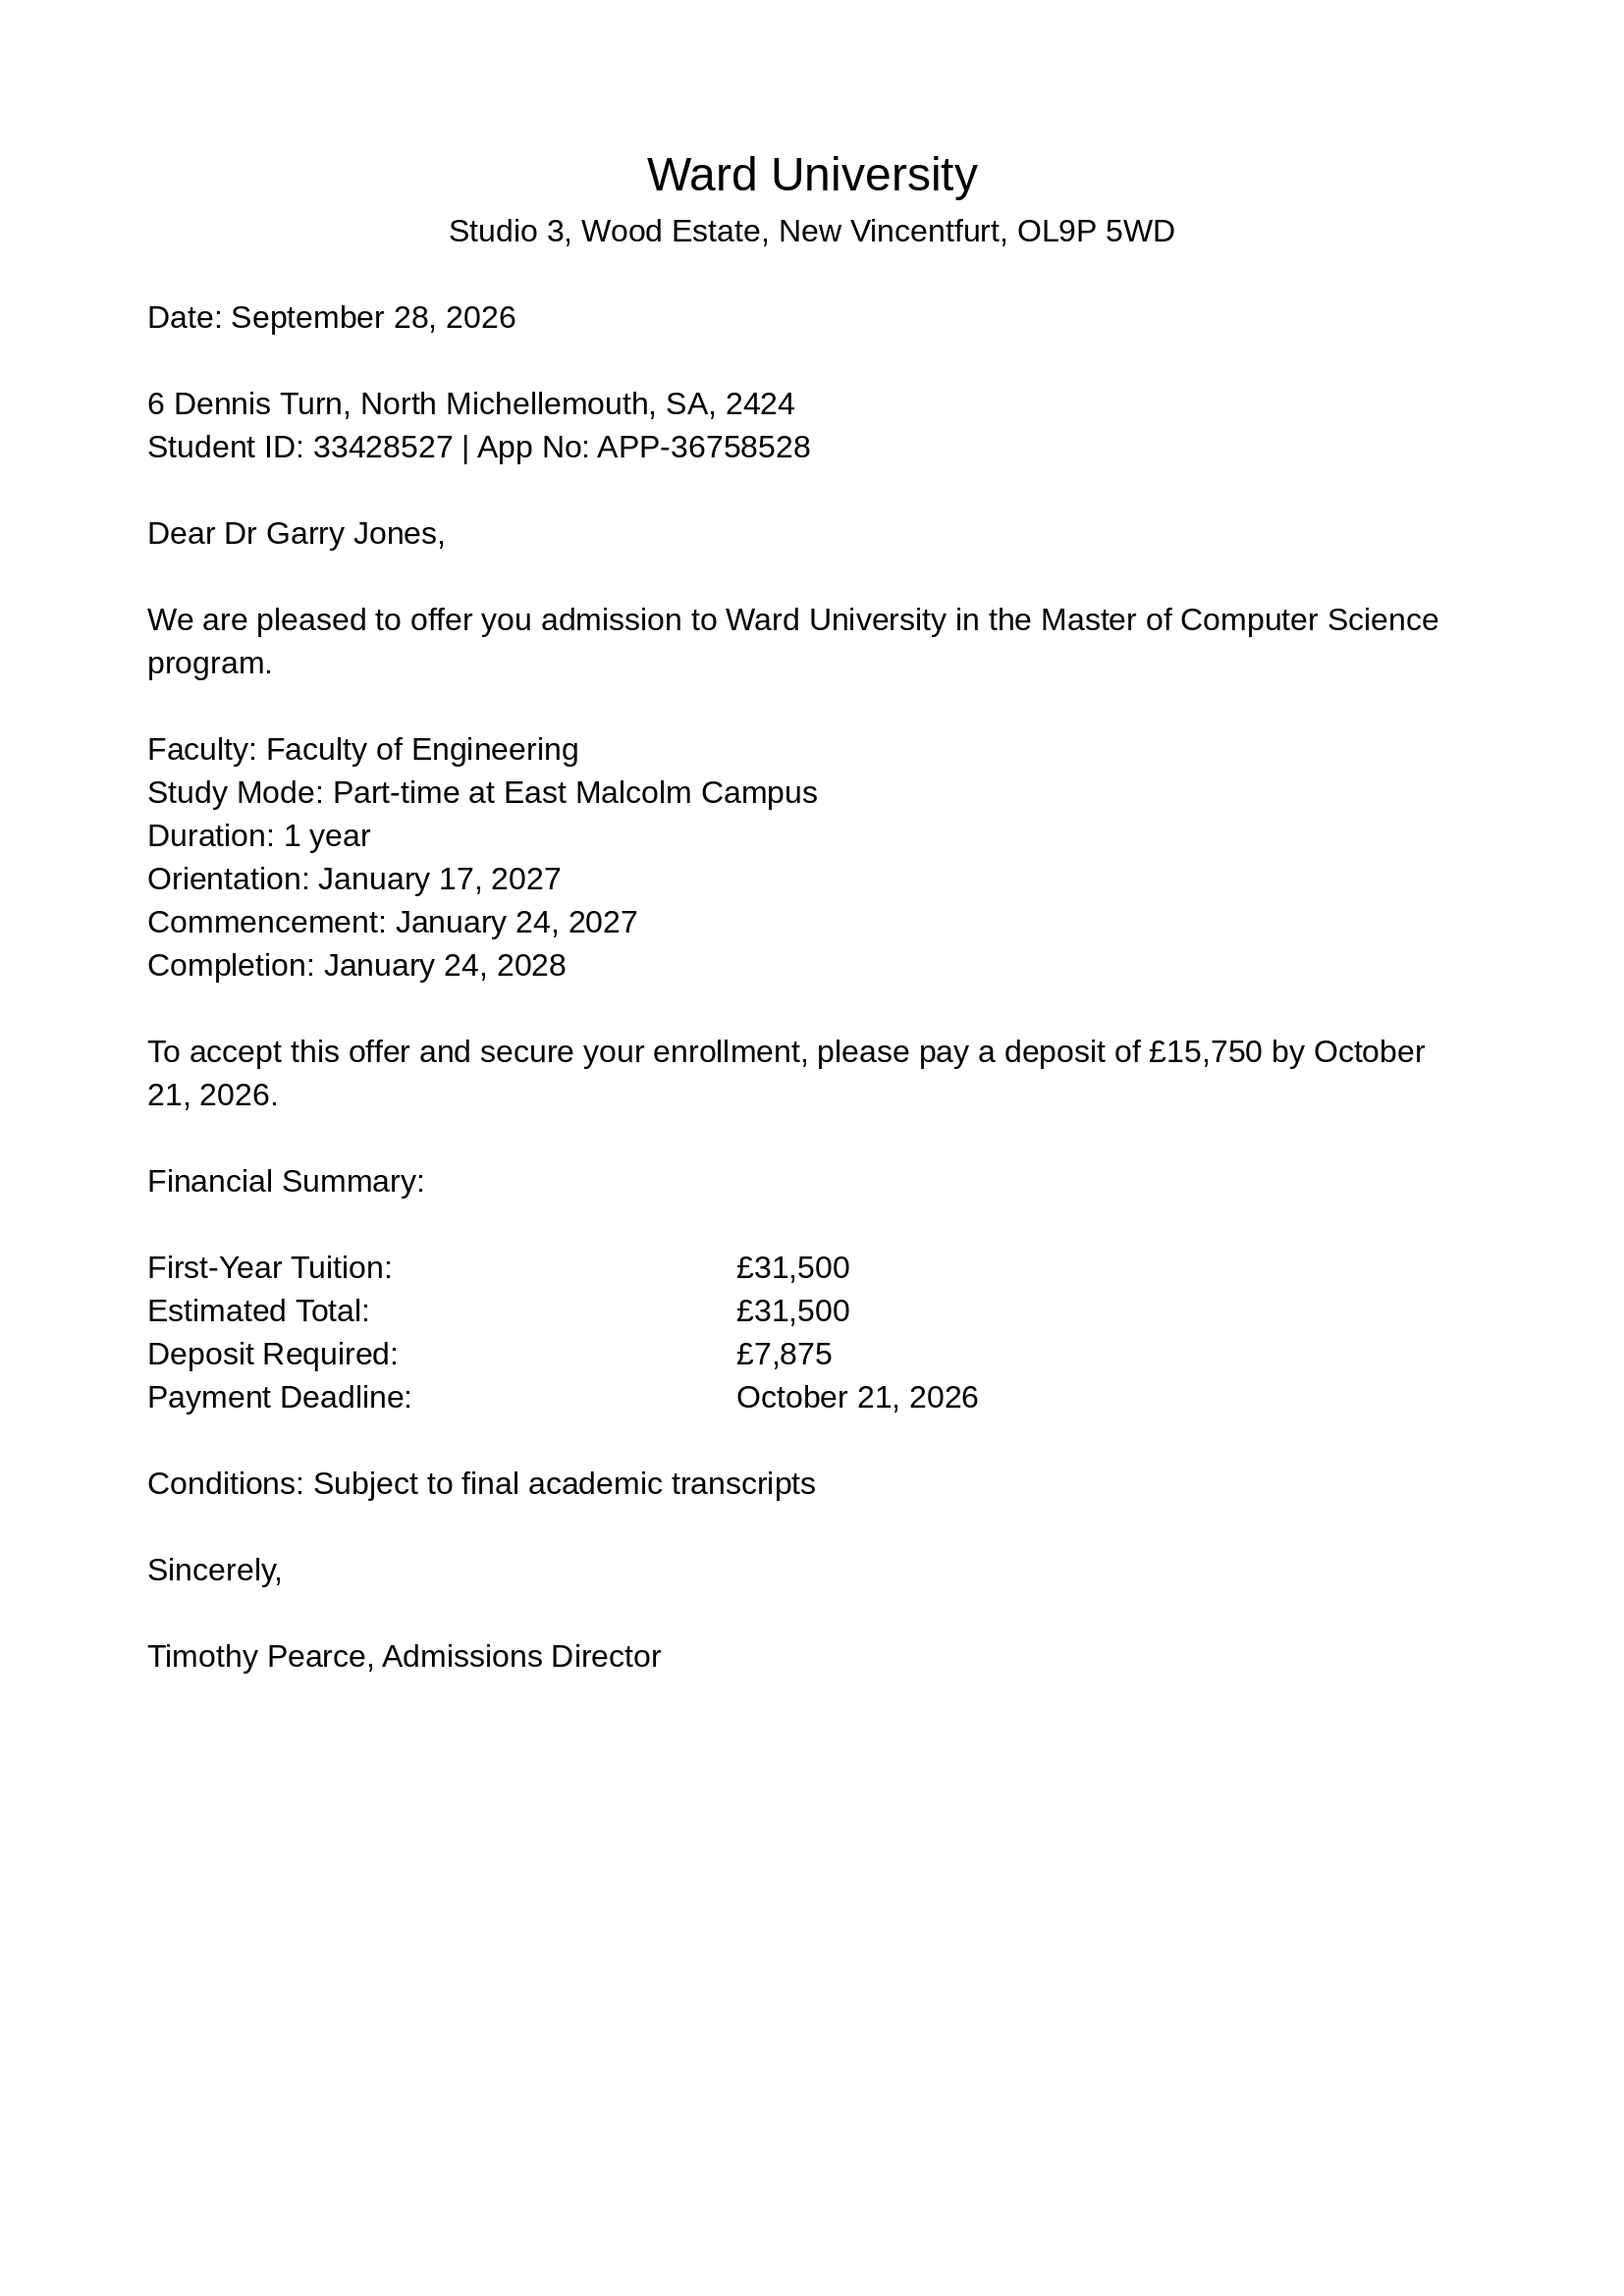

In [3]:
clean_offer = make_clean_offer()
altered_offer = make_inconsistent_offer("altered_amount")

clean_path = samples_dir / "clean_letter.png"
altered_path = samples_dir / "altered_amount_letter.png"

render_offer(clean_offer, template_01, clean_path)
render_offer(altered_offer, template_01, altered_path)

In [4]:
clean_text = pytesseract.image_to_string(Image.open(clean_path))
altered_text = pytesseract.image_to_string(Image.open(altered_path))

print(clean_text)
print("=" * 80)
print(altered_text)

University of Allanside
Flat 4, Bartlett Mount, Bernardport, W15 OET

Date: May 27, 2026

131 Johnson Quadrangle, Patrickburgh, ACT, 4388
Student ID: 40611780 | App No: APP-90552823

Dear Steven Jennings,

We are pleased to offer you admission to University of Allanside in the Master of Business
Administration program.

Faculty: Faculty of Business

Study Mode: Part-time at West Dianemouth Campus
Duration: 1 year

Orientation: September 07, 2026

Commencement: September 14, 2026

Completion: September 14, 2027

To accept this offer and secure your enrollment, please pay a deposit of £4,450 by June 15,
2026.

Financial Summary:

First-Year Tuition: £44,500
Estimated Total: £44,500
Deposit Required: £4,450
Payment Deadline: June 15, 2026

Conditions: None
Sincerely,

Jack Harris, Admissions Director

Ward University
Studio 3, Wood Estate, New Vincentfurt, OL9P 5WD

Date: September 28, 2026

6 Dennis Turn, North Michellemouth, SA, 2424
Student ID: 33428527 | App No: APP-36758528

Dear Dr 

In [5]:
print("clean missing:", check_ocr(clean_offer, clean_text, template_01))
print("altered missing:", check_ocr(altered_offer, altered_text, template_01))

clean missing: {}
altered missing: {}


In [6]:
set_seed(42)
for doc_type, kind in DOC_TYPES.items():
    doc = kind.make_inconsistent("altered_amount")
    for template in kind.templates:
        render_document(doc, template, samples_dir / f"{template['template_id']}.png")

Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/offer_01.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/offer_02.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/offer_03.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/transcript_01.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/transcript_02.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/transcript_03.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/bank_01.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/bank_02.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/bank_03.png


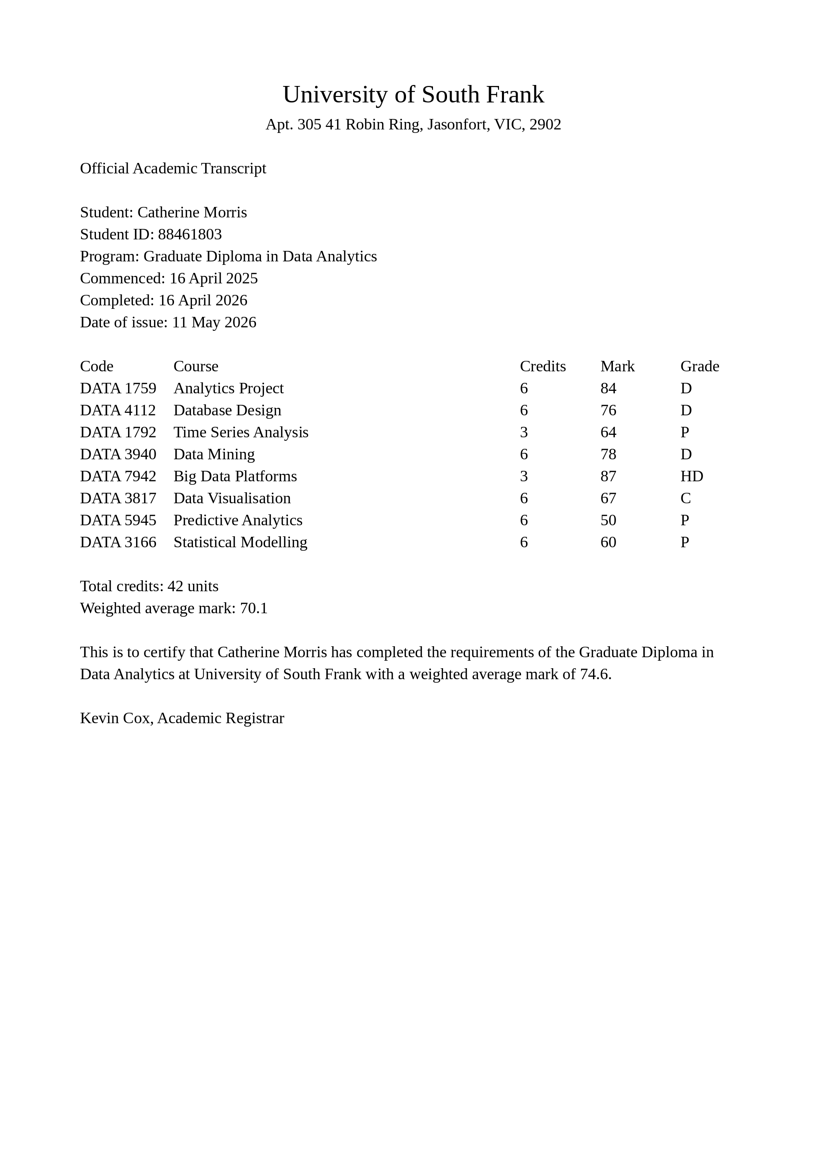

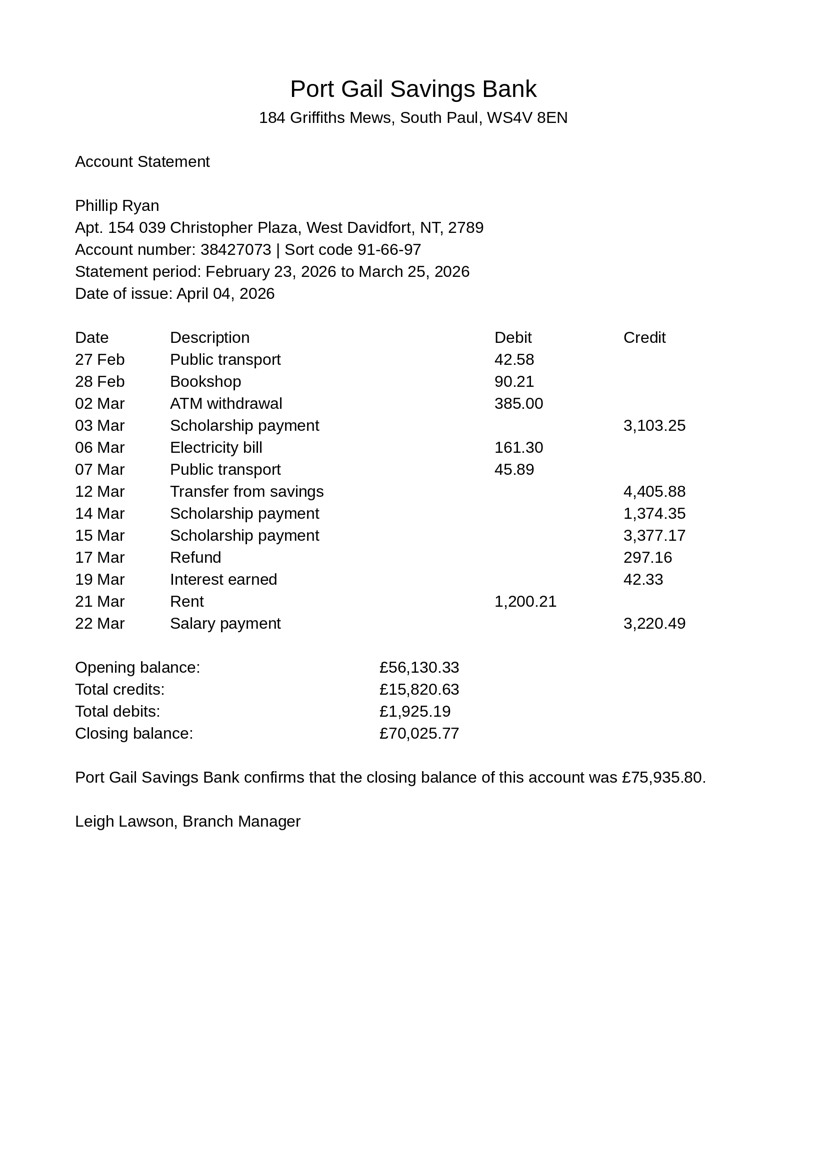

In [7]:
for name in ["transcript_01", "bank_02"]:
    page = Image.open(samples_dir / f"{name}.png")
    display(page.resize((page.width // 2, page.height // 2)))

In [6]:
STRENGTHS = [0, 0.25, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 1]

set_seed(42)
offers = make_letters(100)
sweep = run_ocr(offers, template_01, STRENGTHS)

for strength in STRENGTHS:
    degrade(render_offer(offers[0], template_01), strength, DEGRADE_SEED).save(samples_dir / f"degrade_{strength:.2f}.png")

strength_summary(sweep)

,copies_read,copies_total,altered_value_ocr_ok,ocr_accuracy
strength,,,,
0.00,1200,1200,1.0,1.000000
0.25,1186,1200,1.0,0.988333
0.50,1183,1200,0.98,0.985833
0.55,1183,1200,0.98,0.985833
0.60,1168,1200,0.98,0.973333
0.65,1171,1200,0.98,0.975833
0.70,1171,1200,0.96,0.975833
0.75,1150,1200,0.94,0.958333
1.00,1076,1200,0.84,0.896667


In [7]:
set_seed(7)
gap_offers = make_letters(400)
gap = run_ocr(gap_offers, template_01, [0.5, 0.75])

ocr_accuracy(gap, ['strength', 'label']).unstack()

label,altered,clean
strength,,
0.50,0.98125,0.983750
0.75,0.94125,0.947083


In [8]:
label_gap_tests(gap)

,clean,altered,letters_per_group,z_test_p (copies as units),welch_t_p (letters as units)
strength,,,,,
0.50,0.983750,0.98125,200,0.50896,0.509735
0.75,0.947083,0.94125,200,0.37880,0.463366


In [9]:
gap_swapped = run_ocr(gap_offers, template_01, [0.75], seeds=swapped_seeds(len(gap_offers)))

pd.DataFrame({
    'original seeds': ocr_accuracy(gap[gap['strength'] == 0.75], 'label'),
    'swapped seeds': ocr_accuracy(gap_swapped, 'label'),
})

,original seeds,swapped seeds
label,,
altered,0.941250,0.947917
clean,0.947083,0.952083


In [10]:
ablate_one_at_a_time(offers, template_01, 0.75)

all effects        0.958333
rotation only      1.000000
blur only          1.000000
resolution only    1.000000
noise only         1.000000
stroke only        1.000000
threshold only     1.000000
specks only        0.987500
Name: ocr_accuracy, dtype: float64

In [11]:
ablate_leave_one_out(offers, template_01, 0.75)

all effects           0.958333
without rotation      0.965000
without blur          0.957500
without resolution    0.984167
without noise         0.952500
without stroke        0.964167
without threshold     0.972500
without specks        0.974167
Name: ocr_accuracy, dtype: float64

In [12]:
tobacco_letters = load_tobacco('Letter')
tobacco_conf = pd.Series(page_confidences(to_200_dpi(ex['image']) for ex in tobacco_letters), name='tobacco')

print(f"{len(tobacco_conf)} Tobacco letters, {tobacco_conf.isna().sum()} with no text found")
tobacco_conf.describe()

567 Tobacco letters, 0 with no text found


count    567.000000
mean      88.250195
std        6.092167
min       45.342593
25%       85.717763
50%       90.333333
75%       92.347945
max       95.345291
Name: tobacco, dtype: float64

In [13]:
compare_confidence(sweep, tobacco_conf, 'tobacco').round(3)

,no_text,q10,q25,q50,q75,q90,ks_vs_reference
tobacco,0.0,80.833,85.718,90.333,92.348,93.566,0.000
sad-syn 0.0,0.0,95.115,95.189,95.288,95.364,95.440,0.979
sad-syn 0.25,0.0,92.320,93.331,93.957,94.689,95.093,0.673
sad-syn 0.5,0.0,90.400,91.653,92.834,93.685,94.319,0.445
sad-syn 0.55,0.0,90.115,91.825,92.992,93.740,94.245,0.454
sad-syn 0.6,0.0,90.017,91.022,92.463,93.475,94.298,0.397
sad-syn 0.65,0.0,88.723,90.647,92.153,93.139,93.925,0.320
sad-syn 0.7,0.0,89.114,90.063,91.477,92.795,93.646,0.306
sad-syn 0.75,0.0,88.420,89.510,91.175,92.738,93.846,0.276
sad-syn 1.0,0.0,81.833,86.144,88.966,91.143,92.542,0.189


In [3]:
CANDIDATES = {
    'A: uniform 0.6-1.0': [(1, 0.6, 1.0)],
    'B: uniform 0.7-1.2': [(1, 0.7, 1.2)],
    'C: 75% 0.6-0.9 + 25% 0.9-1.4': [(0.75, 0.6, 0.9), (0.25, 0.9, 1.4)],
}

set_seed(11)
candidate_offers = make_letters(400)
candidate_results = {name: run_ocr_sampled(candidate_offers, template_01, mixture) for name, mixture in CANDIDATES.items()}

compare_candidates(candidate_results, tobacco_conf, 'tobacco').round(3)

,ks_vs_reference,mean_strength,no_text,ocr_accuracy,q10,q25,q50,q75,q90
tobacco,0.000,NaN,0.0,NaN,80.833,85.718,90.333,92.348,93.566
A: uniform 0.6-1.0,0.202,0.804,0.0,0.942,86.712,88.826,90.917,92.766,93.807
B: uniform 0.7-1.2,0.127,0.955,0.0,0.871,79.841,85.547,89.225,91.878,93.294
C: 75% 0.6-0.9 + 25% 0.9-1.4,0.162,0.845,0.0,0.905,85.266,88.362,90.714,92.511,93.744


In [4]:
pd.DataFrame({name: ocr_accuracy(results, 'label') for name, results in candidate_results.items()})

,A: uniform 0.6-1.0,B: uniform 0.7-1.2,C: 75% 0.6-0.9 + 25% 0.9-1.4
label,,,
altered,0.948333,0.894167,0.899583
clean,0.936667,0.847917,0.910833


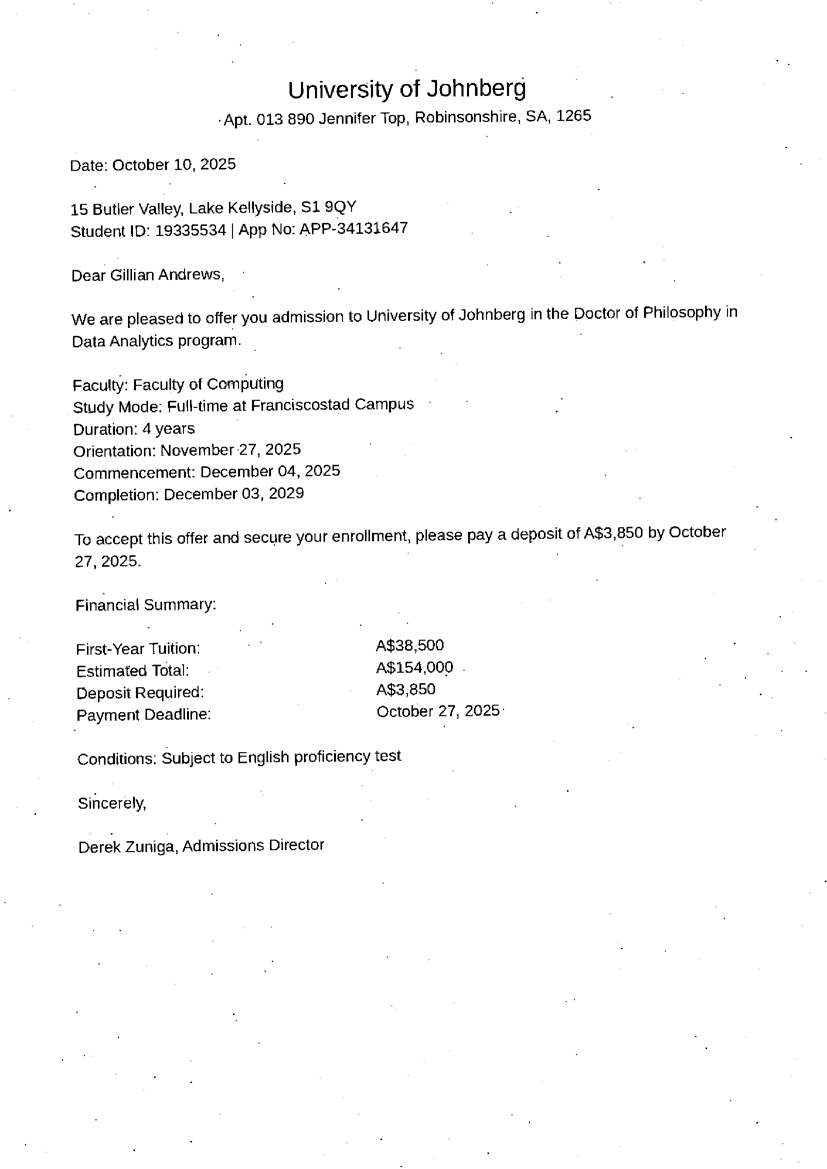

In [14]:
example = Image.open(samples_dir / "degrade_0.50.png")
display(example.resize((example.width // 2, example.height // 2)))

In [8]:
manifest = pd.read_csv(DATA_DIR / "sad_syn" / "manifest.csv")
manifest['accuracy'] = manifest['copies_read'] / manifest['copies_total']

display(manifest.groupby(['split', 'doc_type', 'label']).size().unstack())
manifest.groupby(['doc_type', 'split', 'template']).agg(
    images=('label', 'size'),
    ocr_accuracy=('accuracy', 'mean'),
    median_confidence=('mean_confidence', 'median'),
    altered_value_ocr_ok=('altered_value_ocr_ok', 'mean'),
).round(3)

label                 altered  clean
split doc_type                      
test  bank_statement       75     75
      offer_letter         75     75
      transcript           75     75
train bank_statement      350    350
      offer_letter        350    350
      transcript          350    350
val   bank_statement       75     75
      offer_letter         75     75
      transcript           75     75

images  ocr_accuracy  median_confidence  \
doc_type       split template                                                 
bank_statement test  bank_03           150         0.807             83.898   
               train bank_01           700         0.745             85.557   
               val   bank_02           150         0.843             83.452   
offer_letter   test  offer_03          150         0.868             90.033   
               train offer_01          700         0.898             89.376   
               val   offer_02          150         0.941             91.392   
transcript     test  transcript_03     150         0.945             88.597   
               train transcript_01     700         0.952             87.886   
               val   transcript_02     150         0.942             89.348   

                                   altered_value_ocr_ok  
doc_type       split template                            
bank_statement test  bank_03                   0.773333  
               train bank_01                       0.76  
               val   bank_02                   0.853333  
offer_letter   test  offer_03                  0.773333  
               train offer_01                  0.828571  
               val   offer_02                  0.946667  
transcript     test  transcript_03                 0.96  
               train transcript_01             0.957143  
               val   transcript_02             0.933333

In [1]:
from sad_syn.degrade import draw_strength

[draw_strength(10_000) for _ in range(5)]

[0.7177591501302072,
 0.7177591501302072,
 0.7177591501302072,
 0.7177591501302072,
 0.7177591501302072]